# Soccer Data Analysis: Team Performance and Match Outcomes

## 1. Introduction

* Football (soccer) generates a large amount of data about matches, teams, and player performance. Analyzing this data helps us understand team performance and identify patterns in match outcomes.

* In this project, I use Python to analyze soccer match data, focusing on home wins, away wins, and total wins. The analysis uses data manipulation and visualization techniques to compare team performance and communicate key findings.

## 2. Objectives

- Analyze soccer match data using Python.
- Explore team performance based on home and away victories.
- Compare teams based on total wins.
- Visualize team performance using charts.
- Draw meaningful conclusions from the analysis.

## Importing Libraries
- **Matplotlib:** Used to create and customize charts and graphs.
- **SQLite3:** Used to connect to and interact with SQLite databases.


In [336]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sqlite3 

## 2. Loading the Dataset

The soccer dataset is stored in an SQLite database named `database.sqlite`.

- `sqlite3.connect()` establishes a connection to the SQLite database.
- `pd.read_sql_query()` executes an SQL query to retrieve all records from the `match` table and loads the results into a Pandas DataFrame named `df`.
- `df.head()` displays the first five rows to provide an initial preview of the dataset.



In [337]:
conn = sqlite3.connect("database.sqlite")

df = pd.read_sql_query("select * from match", conn)
df.head()

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,...,4.00,1.65,3.40,4.50,1.78,3.25,4.00,1.73,3.40,4.20
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,...,3.80,2.00,3.25,3.25,1.85,3.25,3.75,1.91,3.25,3.60
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,...,2.50,2.35,3.25,2.65,2.50,3.20,2.50,2.30,3.20,2.75
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,...,7.50,1.45,3.75,6.50,1.50,3.75,5.50,1.44,3.75,6.50
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,...,1.73,4.50,3.40,1.65,4.50,3.50,1.65,4.75,3.30,1.67


In [338]:
df.shape

(25979, 115)

In [339]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25979 entries, 0 to 25978
Columns: 115 entries, id to BSA
dtypes: float64(96), int64(9), object(10)
memory usage: 22.8+ MB


In [340]:
df.isnull().sum()

id                0
country_id        0
league_id         0
season            0
stage             0
              ...  
GBD           11817
GBA           11817
BSH           11818
BSD           11818
BSA           11818
Length: 115, dtype: int64

## 3. Selecting Relevant Columns

The original dataset contains multiple columns, Selecting only required columns for analysis
The selected columns include:

- **Match identification:** `id`, `match_api_id`
- **Competition details:** `country_id`, `league_id`, `season`, `stage`, `date`
- **Team identification:** `home_team_api_id`, `away_team_api_id`
- **Match results:** `home_team_goal`, `away_team_goal`


In [341]:
df1 = df[['id',
'country_id'
,'league_id'
,'season'
,'stage'
,'date'
,'match_api_id'
,'home_team_api_id'
,'away_team_api_id'
,'home_team_goal',
'away_team_goal']].copy()

In [342]:
df1.head()

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,1
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,0
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,3
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,0
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,3


In [343]:
df1.isnull().sum()

id                  0
country_id          0
league_id           0
season              0
stage               0
date                0
match_api_id        0
home_team_api_id    0
away_team_api_id    0
home_team_goal      0
away_team_goal      0
dtype: int64

In [344]:
df1.duplicated().sum()

np.int64(0)

## 4. Creating a Total Goals Column

Total Goals = Home Team Goals + Away Team Goals

This column helps identify the total number of goals scored in each match.

In [345]:
df1['total_goals'] = (df1['home_team_goal'] + df1['away_team_goal'])

### Average Goals per Match by Season

This analysis calculates the average number of goals scored per match across different football seasons.


In [346]:
avg_goals_per_season = df1.groupby('season')['total_goals'].mean()

avg_goals_per_season.sort_values(ascending=False).head(10)

season
2012/2013    2.772699
2013/2014    2.766821
2015/2016    2.754660
2011/2012    2.716460
2010/2011    2.683742
2014/2015    2.675789
2009/2010    2.672446
2008/2009    2.607336
Name: total_goals, dtype: float64

In [347]:
df1.head()

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal,total_goals
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,1,2
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,0,0
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,3,3
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,0,5
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,3,4


## 5. Creating the Match Result Column

To identify the outcome of each match, I create a new column named `match_result`.

The result is determined by comparing the goals scored by the home team and the away team.

- **Home Wins:** The home team scores more goals than the away team.
- **Away Wins:** The away team scores more goals than the home team.
- **Draw:** Both teams score the same number of goals.

In [348]:
df1['match_result'] = np.where(
    df1['home_team_goal'] > df1['away_team_goal'],
    'Home Wins',
    np.where(
        df1['home_team_goal'] < df1['away_team_goal'],
        'Away Wins',
        'Draw'
    )
)

In [349]:
df1['match_result'].value_counts() #This provides the total number of home wins, away wins, and draws in the dataset.


match_result
Home Wins    11917
Away Wins     7466
Draw          6596
Name: count, dtype: int64

## 7. Visualizing the Home Wins and Away Wins

- **X-axis:** Match result categories (Home Wins, Away Wins, and Draws).
- **Y-axis:** Number of matches in each category.
- **Figure size:** Set to 7 × 5 inches for clear visualization.



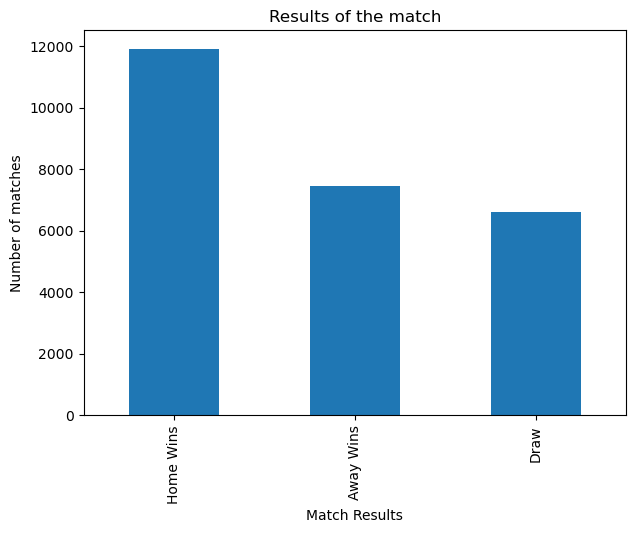

In [350]:
df1['match_result'].value_counts().plot(kind = 'bar', figsize = (7,5))

plt.title("Results of the match")
plt.xlabel("Match Results")
plt.ylabel("Number of matches")
plt.show()

### Avove Bar Graph conclude that: 

The analysis of 25,979 football matches shows that 45.9% ended in home wins, compared with 28.7% in away wins and 25.4% in draws.

Home victories were considerably more frequent than away victories, suggesting a home advantage in the dataset.

This shows that factors such as familiarity with the home stadium, crowd support, may benefits the home team to produce high performance and increase the chance of probablity.

## 8. Total Goals Scored by Home and Away Teams

In this section, I calculate the total number of goals scored by home teams and away teams across all matches in the dataset.

- **Home Team Goals:** Sum of all goals scored by home teams.
- **Away Team Goals:** Sum of all goals scored by away teams.

This comparison helps determine which group scored more goals overall and provides further insight into the potential home advantage observed in match outcomes.

In [351]:
print("Total Goal Scored by Home Team :",df1['home_team_goal'].sum())
print("Total Goal Scored by Away Team :",df1['away_team_goal'].sum())

Total Goal Scored by Home Team : 40127
Total Goal Scored by Away Team : 30160


## 9. Calculating Average Goals Scored by Home and Away Teams



In [352]:
print("Average Goals Scored by Home Team :",df1['home_team_goal'].mean())
print("Average Goals Scored by Away Team :",df1['away_team_goal'].mean())

Average Goals Scored by Home Team : 1.5445937103044767
Average Goals Scored by Away Team : 1.1609376804341969


## 10. Selecting the Top 10 Highest-Scoring Matches


In [353]:
top_matches = df1.sort_values(ascending= False, by='total_goals').head(10)
#top_matches = top_matches.to_frame()

### 10.1 Creating a Match Summary DataFrame

A new DataFrame named `match_summary` containing only the columns relevant to match scores and outcomes.

The selected columns include:

- **Home Team ID:** Identifier of the home team.
- **Away Team ID:** Identifier of the away team.
- **Home Team Goals:** Number of goals scored by the home team.
- **Away Team Goals:** Number of goals scored by the away team.
- **Total Goals:** Combined goals scored by both teams.
- **Match Result:** Indicates whether the match ended in a home win, away win, or draw.

The `.copy()` method creates an independent copy of the selected columns.
 and prepares the data for further analysis.

In [354]:
match_summary  = df1[['home_team_api_id','away_team_api_id','home_team_goal','away_team_goal','total_goals','match_result']].copy()

In [355]:
match_summary = match_summary.rename(columns={
    ' ': 'match_id',
    'home_team_api_id': 'Home Team ID',
    'away_team_api_id': 'Away Team ID',
    'home_team_goal': 'Home Goals',
    'away_team_goal': 'Away Goals',
    'total_goals': 'Total Goals',
    'match_result': 'Match Result'
})

### 10.2 Displaying the Top 10 Highest-Scoring Matches

The index of the `match_summary` DataFrame is renamed to `MatchID` to make the match records easier to identify.

This analysis helps identify matches with the highest combined goals scored by both teams.


In [356]:
match_summary.index.name = 'MatchID'
match_summary.sort_values(ascending=False, by = 'Total Goals').head(10)


,Home Team ID,Away Team ID,Home Goals,Away Goals,Total Goals,Match Result
MatchID,,,,,,
20106,9927,10251,6,6,12,Draw
24247,8633,8370,10,2,12,Home Wins
9210,9823,9790,9,2,11,Home Wins
3092,10260,9825,8,2,10,Home Wins
3368,9825,10261,7,3,10,Home Wins
23443,8633,8302,7,3,10,Home Wins
13898,8640,10235,10,0,10,Home Wins
24015,8633,7878,9,1,10,Home Wins
24113,8633,8305,7,3,10,Home Wins


#### Interpretation

The table displays the 10 matches with the highest total goals scored by both teams combined. Comparing home and away goals helps identify which team scored more and whether the match ended in a home win, away win, or draw.

This analysis highlights high-scoring matches and provides insight into the outcomes of matches with a large number of goals.

### 10.3 Visualizing Goals in the Top 10 Highest-Scoring Matches

A grouped bar chart is created to compare the goals scored by home teams and away teams in the top 10 highest-scoring matches.

- **X-axis:** Match IDs used to identify individual matches.
- **Y-axis:** Number of goals scored.
- **Away Team Goals:** Represents goals scored by the away team.
- **Home Team Goals:** Represents goals scored by the home team.

The chart uses Matplotlib to visualize both teams' scoring performance side by side for each match.

This comparison makes it easier to identify which team scored more goals in each match and understand the scoring differences between home and away teams.

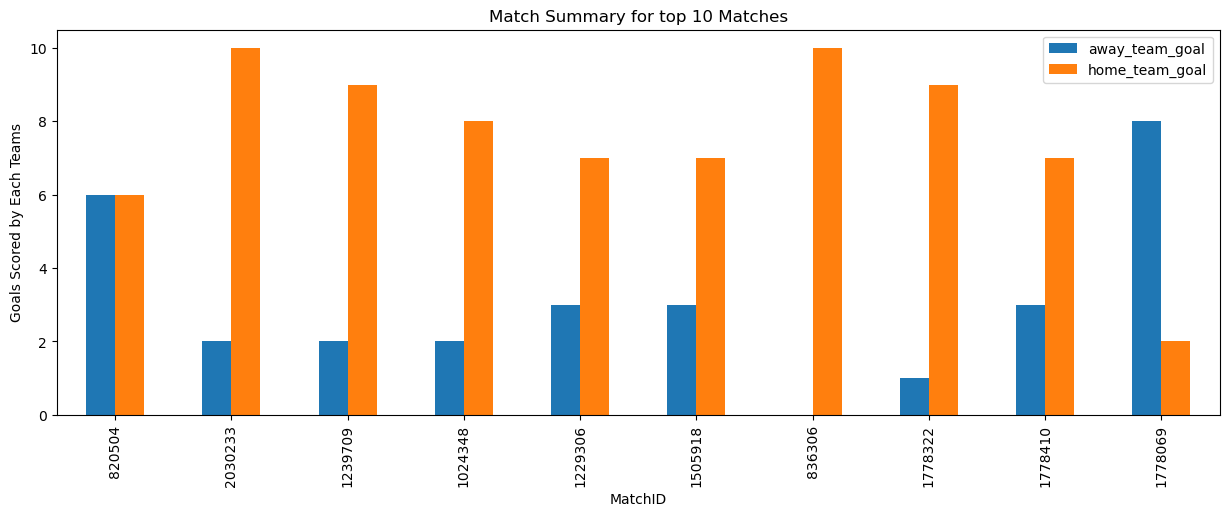

In [357]:
top_matches.plot(
    x = 'match_api_id', y = ['away_team_goal','home_team_goal'],
    kind = 'bar',figsize = (15,5), 
    title = "Match Summary for top 10 Matches" 
)
plt.xlabel("MatchID")
plt.ylabel("Goals Scored by Each Teams")
plt.show()

## 11. Identifying the Top 10 Seasons by Total Goals

In this section, I analyze the total number of goals scored across different football seasons.

This analysis helps identify which seasons recorded the highest overall goal counts.


In [358]:
season_goals = df1.groupby('season')['total_goals'].sum()
season_goals.sort_values(ascending= False).head(10)


season
2015/2016    9162
2012/2013    9039
2014/2015    8897
2010/2011    8749
2011/2012    8747
2008/2009    8672
2009/2010    8632
2013/2014    8389
Name: total_goals, dtype: int64

In [359]:
# print(type(season_goals))

## 12. Comparing Home and Away Goals Across Seasons

In this section, I calculate the total goals scored by home teams and away teams across different football seasons.


In [360]:
home_season = df1.groupby('season')['home_team_goal'].sum()
away_season = df1.groupby('season')['away_team_goal'].sum()

In [361]:
home_season.sort_values(ascending= False).head(10)

season
2015/2016    5135
2011/2012    5064
2014/2015    5055
2012/2013    5053
2010/2011    5048
2008/2009    5007
2009/2010    4978
2013/2014    4787
Name: home_team_goal, dtype: int64

In [362]:
away_season.sort_values(ascending= False).head(10)

season
2015/2016    4027
2012/2013    3986
2014/2015    3842
2010/2011    3701
2011/2012    3683
2008/2009    3665
2009/2010    3654
2013/2014    3602
Name: away_team_goal, dtype: int64

## 12.1  Making it into a DataFrame align side by side to make it easier to visualize.

In [363]:
season_comparison = pd.DataFrame({
    'Home Goals': home_season,
    'Away Goals': away_season
})

In [364]:
top_10_seasons = season_comparison.sort_values(ascending= False, by= ['Home Goals','Away Goals']).head(10)

In [365]:
top_10_seasons

,Home Goals,Away Goals
season,,
2015/2016,5135,4027
2011/2012,5064,3683
2014/2015,5055,3842
2012/2013,5053,3986
2010/2011,5048,3701
2008/2009,5007,3665
2009/2010,4978,3654
2013/2014,4787,3602


In [366]:
top_10_seasons.index.name = 'season'

In [367]:
top_10_seasons.columns

Index(['Home Goals', 'Away Goals'], dtype='object')

### 12.2 Visualizing Home vs Away Goals for the Top 10 Seasons

This chart compares home and away goals across the top 10 seasons. It helps identify scoring differences between home and away teams and determine whether home teams consistently scored more goals across these seasons.

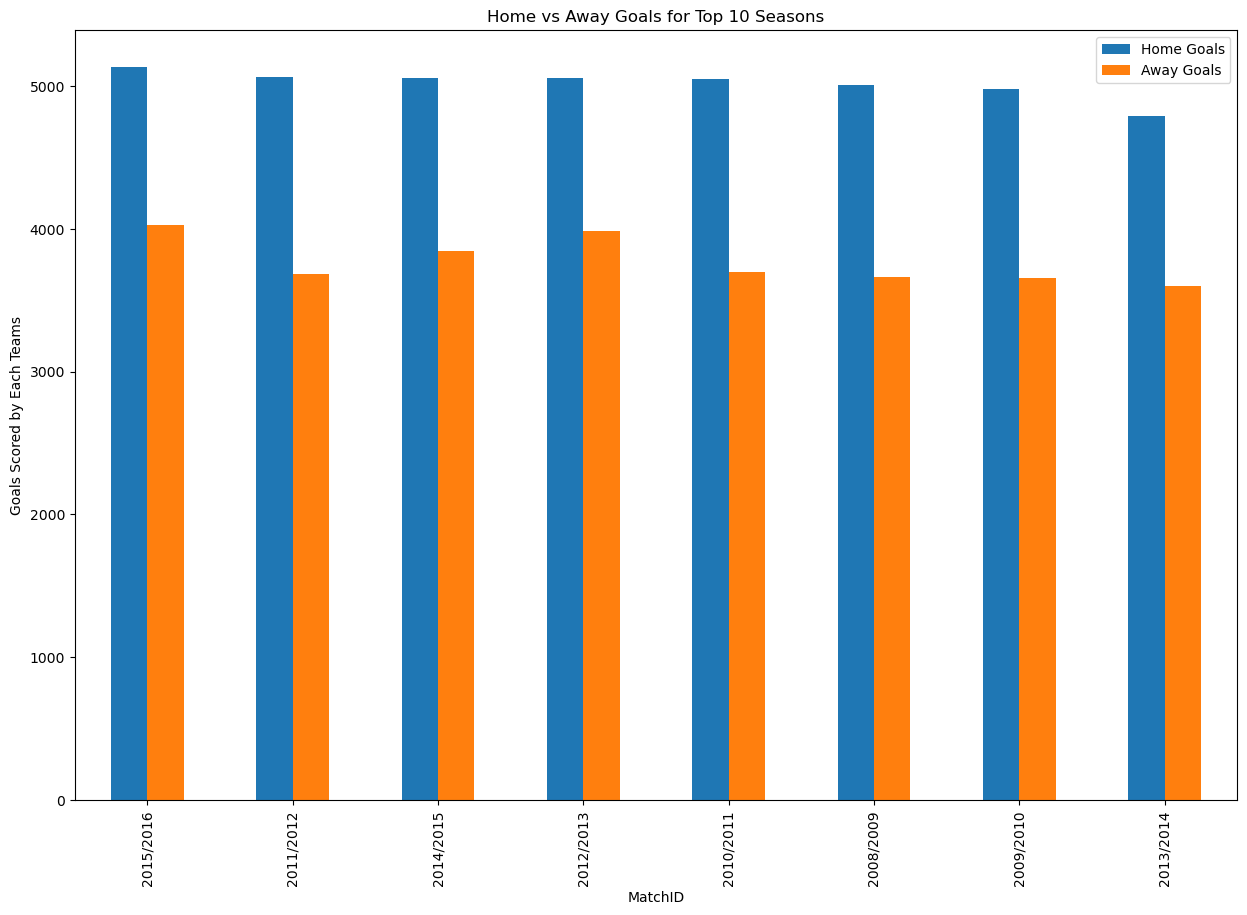

In [368]:
top_10_seasons.plot(
    y=['Home Goals', 'Away Goals'],
    kind='bar',
    figsize=(15, 10),
    title='Home vs Away Goals for Top 10 Seasons'
)
plt.xlabel("MatchID")
plt.ylabel("Goals Scored by Each Teams")
plt.show()

## 13. Loading Team Data from DATABASE:

Load `Team` table from the SQLite database to retrieve team information.

The `team_api_id` and `team_long_name` columns are selected to connect team IDs with their corresponding names. Displaying the first five rows helps verify the data and prepares it for further analysis using team names instead of numeric IDs.

In [369]:
teams = pd.read_sql_query("Select * from Team", conn)

In [370]:
teams[['team_api_id','team_long_name']].head()

,team_api_id,team_long_name
0,9987,KRC Genk
1,9993,Beerschot AC
2,10000,SV Zulte-Waregem
3,9994,Sporting Lokeren
4,9984,KSV Cercle Brugge


In [371]:
teams = teams.rename(columns= {'team_api_id' : 'Team ID',
                              'team_long_name': 'Team Name'})

In [372]:
home_goals = df1.groupby('home_team_api_id')['home_team_goal'].sum()
# away_goals = df1.groupby('away_team_api_id')['away_team_goal'].sum()

## 14. Analyzing Home Team Performance

This section focuses on analyzing goals scored by home teams using team names instead of numeric IDs. This helps identify high-scoring teams and compare their performance across matches.

In [373]:
home_goals = pd.merge(  
    home_goals, teams[['Team ID','Team Name']], 
    how = 'left', 
    left_on = 'home_team_api_id', 
    right_on = 'Team ID'
)

### 14.1 Identifying the Top 10 Home Teams by Goals Scored

This analysis identifies the top 10 home teams based on the total goals scored in home matches. Sorting the data in descending order helps highlight the teams with the highest goal counts and compare their attacking performance when playing at home.
    

In [374]:
team_with_max_goal = home_goals.sort_values(ascending= False, by = 'home_team_goal').head(10)
team_with_max_goal

,home_team_goal,Team ID,Team Name
140,505,8633,Real Madrid CF
141,495,8634,FC Barcelona
233,389,9925,Celtic
191,382,9823,FC Bayern Munich
145,370,8640,PSV
88,365,8456,Manchester City
131,360,8593,Ajax
236,344,9931,FC Basel
284,338,10260,Manchester United
87,333,8455,Chelsea


### 14.2 Identifying the Home Team with the Most Goals

This step displays the name of the home team with the highest number of goals and its corresponding goal count.

The results from `team_with_max_goal` are used to retrieve the top team's name and goals scored, making it easier to identify the strongest goal-scoring team when playing at home.

In [375]:
print(f"Home Team with Maximum Goals: {team_with_max_goal['Team Name'].head(1)} with {team_with_max_goal['home_team_goal'].head(1)} goals \n" )

Home Team with Maximum Goals: 140    Real Madrid CF
Name: Team Name, dtype: object with 140    505
Name: home_team_goal, dtype: int64 goals 



In [376]:
#df1.columns

## 15. Creating the seperate dataframe 

* This is done to keep the further analysis seperate and makes easy.
* Selected only required columns
  

In [377]:
df2 = df1[['season', 'home_team_api_id','away_team_api_id','home_team_goal','away_team_goal','total_goals','match_result']].copy()

### 15.1 Mapping Home Team Names to Match Records

This step merges the match data with the team information table to associate each home team ID with its corresponding team name.

The left join preserves the match records from `df2` and adds the matching team name from `teams`. This makes it easier to analyze match results and compare team performance using readable names instead of numeric IDs.

In [378]:
df2 = pd.merge(  
    df2[['season', 'home_team_api_id','away_team_api_id','home_team_goal','away_team_goal','total_goals','match_result']], teams[['Team ID','Team Name']], 
    how = 'left', 
    left_on = 'home_team_api_id', 
    right_on = 'Team ID'
)

In [379]:
df2.head()

,season,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal,total_goals,match_result,Team ID,Team Name
0,2008/2009,9987,9993,1,1,2,Draw,9987,KRC Genk
1,2008/2009,10000,9994,0,0,0,Draw,10000,SV Zulte-Waregem
2,2008/2009,9984,8635,0,3,3,Away Wins,9984,KSV Cercle Brugge
3,2008/2009,9991,9998,5,0,5,Home Wins,9991,KAA Gent
4,2008/2009,7947,9985,1,3,4,Away Wins,7947,FCV Dender EH


In [380]:
#df2 = df2.rename(columns={'team_long_name':'Home Team Name'})

### 15.2 Calculating Away Goals and Home Goals scored by Team and Season

This step groups the match data by season and team name to calculate the total goals scored by away teams.

The results help compare teams' scoring performance when playing away from home across different seasons and identify teams that perform well in away matches.

In [381]:
away_goals = df2.groupby(['season','Team Name'])['away_team_goal'].sum()
home_season = df2.groupby(['season','Team Name'])['home_team_goal'].sum()

In [382]:
home_season = home_season.reset_index()
away_goals = away_goals.reset_index() # reset_index is used to reset the index for better merging

In [383]:
# df2.columns

In [384]:
df2.head()

,season,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal,total_goals,match_result,Team ID,Team Name
0,2008/2009,9987,9993,1,1,2,Draw,9987,KRC Genk
1,2008/2009,10000,9994,0,0,0,Draw,10000,SV Zulte-Waregem
2,2008/2009,9984,8635,0,3,3,Away Wins,9984,KSV Cercle Brugge
3,2008/2009,9991,9998,5,0,5,Home Wins,9991,KAA Gent
4,2008/2009,7947,9985,1,3,4,Away Wins,7947,FCV Dender EH


In [385]:
df2 = df2.rename(columns={
    'home_team_api_id' : 'Home Team ID',
    'away_team_api_id' : 'Away Team ID',
    'home_team_goal' : 'Home Team Goal',
    'away_team_goal' : 'Away Team Goal',
})

### 15.4 Combining Home and Away Goals

This step merges the home goals and away goals DataFrames using the `season` and `Team Name` columns.

`Total Goals Scored` calculated by summing up the away goals and home goals

In [386]:
total_goals_per_season = pd.merge(home_season,away_goals, on = ['season','Team Name'])
total_goals_per_season['Total Goals Scored'] = total_goals_per_season['home_team_goal']+total_goals_per_season['away_team_goal']

### 15.5 Identifying the Top 10 Team-Season Records by Goals

This step sorts the combined dataset in descending order by `Total Goals Scored` and displays the top 10 records.

It helps identify which teams scored the most goals in a particular season and compare their overall scoring performance.


In [387]:
total_goals_per_season.sort_values(ascending= False, by = 'Total Goals Scored').head(10)

,season,Team Name,home_team_goal,away_team_goal,Total Goals Scored
689,2011/2012,Real Madrid CF,70,19,89
869,2012/2013,Real Madrid CF,67,21,88
1420,2015/2016,Real Madrid CF,70,16,86
601,2011/2012,FC Barcelona,73,11,84
225,2009/2010,Chelsea,68,14,82
1334,2015/2016,FC Barcelona,67,14,81
1236,2014/2015,Real Madrid CF,65,15,80
1051,2013/2014,Real Madrid CF,63,17,80
970,2013/2014,FC Barcelona,64,15,79
779,2012/2013,FC Barcelona,63,15,78


### 15.6 Verifying Team Goal Totals for a Specific Season

This step filters the dataset to display records for the 2011/2012 season and sorts the teams by total goals scored in descending order.

It helps verify the previous results by checking the goal totals for an individual season and confirming that the teams are ranked correctly.

In [388]:
total_goals_per_season[total_goals_per_season['season'] == '2011/2012'].sort_values(ascending= False,by = 'Total Goals Scored')

,season,Team Name,home_team_goal,away_team_goal,Total Goals Scored
689,2011/2012,Real Madrid CF,70,19,89
601,2011/2012,FC Barcelona,73,11,84
673,2011/2012,PSV,57,20,77
615,2011/2012,FC Utrecht,39,33,72
669,2011/2012,Olympique Lyonnais,44,27,71
...,...,...,...,...,...
677,2011/2012,Podbeskidzie Bielsko-Biała,12,14,26
737,2011/2012,Wisła Kraków,14,11,25
568,2011/2012,Académica de Coimbra,11,12,23
650,2011/2012,Lechia Gdańsk,9,13,22


In [389]:
df2.columns

Index(['season', 'Home Team ID', 'Away Team ID', 'Home Team Goal',
       'Away Team Goal', 'total_goals', 'match_result', 'Team ID',
       'Team Name'],
      dtype='object')

In [390]:
df3.columns

Index(['season', 'Home Team ID', 'Away Team ID', 'Home Team Goal',
       'Away Team Goal', 'Total Goals', 'Team Wins', 'Team ID', 'Team Name'],
      dtype='object')

## 16. Mapping Away Team Names to Match Records

This step merges the match dataset with the team information table to associate each away team ID with its corresponding team name.

A left join is used to retain all match records while adding the matching away team name. This helps analyze match outcomes and goals scored by away teams using readable team names instead of numeric IDs.

In [391]:
df3 = pd.merge(  
    df2[['season', 'Home Team ID','Away Team ID','Home Team Goal','Away Team Goal','total_goals','match_result']], 
    teams[['Team ID','Team Name']], 
    how = 'left', 
    left_on = 'Away Team ID', 
    right_on = 'Team ID'
)

In [392]:
df3.head()

,season,Home Team ID,Away Team ID,Home Team Goal,Away Team Goal,total_goals,match_result,Team ID,Team Name
0,2008/2009,9987,9993,1,1,2,Draw,9993,Beerschot AC
1,2008/2009,10000,9994,0,0,0,Draw,9994,Sporting Lokeren
2,2008/2009,9984,8635,0,3,3,Away Wins,8635,RSC Anderlecht
3,2008/2009,9991,9998,5,0,5,Home Wins,9998,RAEC Mons
4,2008/2009,7947,9985,1,3,4,Away Wins,9985,Standard de Liège


In [393]:
#df2.head()

In [394]:
df3 = df3.rename(columns={
    'home_team_goal' : 'Home Team Goal',
    'away_team_goal' : 'Away Team Goal',
    'total_goals' : 'Total Goals',
    'match_result' : 'Team Wins',
    'team_api_id': 'Team Id',
    'team_long_name' : 'Away Team Name'}
          )


In [395]:
#df2.columns

In [396]:
#df3.columns

## 17. Combining Home and Away Team Information

This step merges the match dataset with the team information table to retrieve the corresponding away team names.

The merge uses the away team ID to match records with the team table while retaining the existing match details, including season, home and away goals, total goals, and match result.

This is done to  prepares the dataset for comparing home and away team performance using team names.

In [397]:
df_combined = pd.merge(
    df2[['season', 'Home Team ID',
                           'Away Team ID','Home Team Goal','Away Team Goal',
                            'total_goals','match_result','Team ID','Team Name']],
    teams[['Team ID', 'Team Name']],
    how='left',
    left_on='Away Team ID',
    right_on='Team ID'
)

In [398]:
# df_combined.columns

In [399]:
df_combined = df_combined.rename(columns={
    'Team Name_x': 'Home Team',
    'Team Name_y' : 'Away Team'
})

In [400]:
# dropped columns which are not required
df_combined = df_combined.drop(columns= {'Team ID_x','Team ID_y'})


In [401]:

#df_combined.sort_values(ascending= False, by = 'total_goals').head(10)

In [402]:
# df_combined.columns

In [403]:
#df_combined.sort_values(ascending=False, by = 'away_team_goal').head(10)

## 18. Identifying Match Winners by Team Name

This step updates the `match_result` column to display the winning team's name instead of a general result category.

The goals scored by the home and away teams are compared to determine the outcome:

- If the home team scores more goals, its name is recorded as the winner.
- If the away team scores more goals, its name is recorded as the winner.
- If both teams score the same number of goals, the result is recorded as a draw.

This makes match results easier to interpret and helps identify winning teams in further analysis.

In [404]:
df_combined['match_result'] = np.where(
    df_combined['Home Team Goal'] > df_combined['Away Team Goal'],
    df_combined['Home Team'],
    np.where(
        df_combined['Home Team Goal'] < df_combined['Away Team Goal'],
        df_combined['Away Team'],
        'Draw'
    )
)

### 18.1 Identifying Losing Teams

This step creates a `Team Loses` column to identify the team that lost each match by comparing the goals scored by the home and away teams.

If the home team scores more goals, the away team is recorded as the loser. If the away team scores more goals, the home team is recorded as the loser. If both teams score the same number of goals, the result is recorded as a draw.

This helps analyze losing teams and compare match outcomes across seasons.

In [405]:
df_combined['Team Loses'] = np.where(
    df_combined['Home Team Goal'] > df_combined['Away Team Goal'],
    df_combined['Away Team'],
    np.where(
        df_combined['Home Team Goal'] < df_combined['Away Team Goal'],
        df_combined['Home Team'],
        'Draw'
    )
)

In [406]:
# df_combined.columns


In [407]:
# df_combined.shape

### 18.2 Identifying the Top 10 Teams by Wins

This step identifies the top best teams in terms of winning. 
It also considers `Home wins` as well as `Away wins`

In [408]:
best_team_by_wins = (
    df_combined.loc[df_combined['match_result']!='Draw', 'match_result'].value_counts().head(10)
)
best_team_by_wins.head()

match_result
FC Barcelona         234
Real Madrid CF       228
Celtic               218
FC Bayern Munich     193
Manchester United    192
Name: count, dtype: int64

### 18.3 Identifying which teams performed bad by means of no of matches they lost.

This step identifies the worst teams in terms of losing. 

In [409]:
top_team_with_most_loses = (
    df_combined.loc[df_combined['Team Loses']!='Draw', 'Team Loses'].value_counts().head(10)
)
top_team_with_most_loses.head()

Team Loses
Kilmarnock      142
Getafe CF       139
Sunderland      134
RCD Espanyol    134
St. Mirren      131
Name: count, dtype: int64

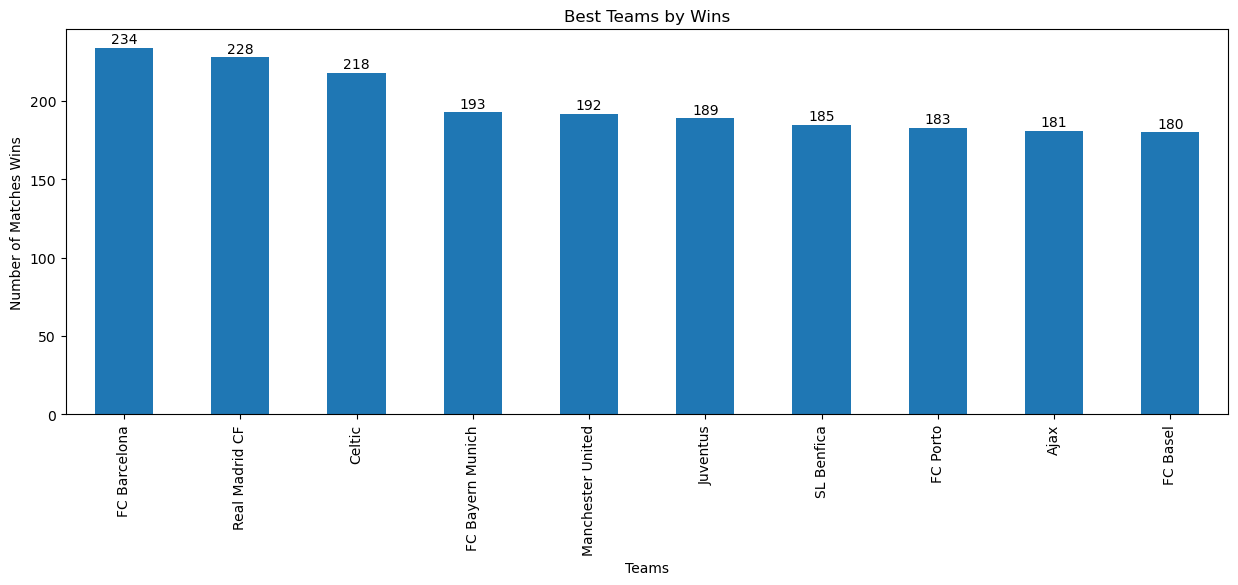

In [410]:

#sns.countplot(data=df1, x='match_result')

ax = best_team_by_wins.head(10).plot(kind = 'bar', figsize = (15,5))

plt.title("Best Teams by Wins")
plt.xlabel("Teams")
plt.ylabel("Number of Matches Wins")
ax.bar_label(ax.containers[0], padding=1)

plt.show()

#### Conclusion 

The bar chart displays the top 10 teams with the highest number of match wins. The team with the tallest bar has recorded the most wins among the selected teams.


* `FC Barcelona` recorded the highest number of wins, with `234 victories`, followed by `Real Madrid CF` with `228 wins` and Celtic with 218 wins.
* `FC Bayern Munich` with 193 and `Manchester United` followed 192 wins, respectively.

These results highlight the teams with the most victories in the dataset. `FC Barcelona` leads the comparison, while the relatively close counts for FC Barcelona and Real Madrid CF indicate strong performance by both teams.

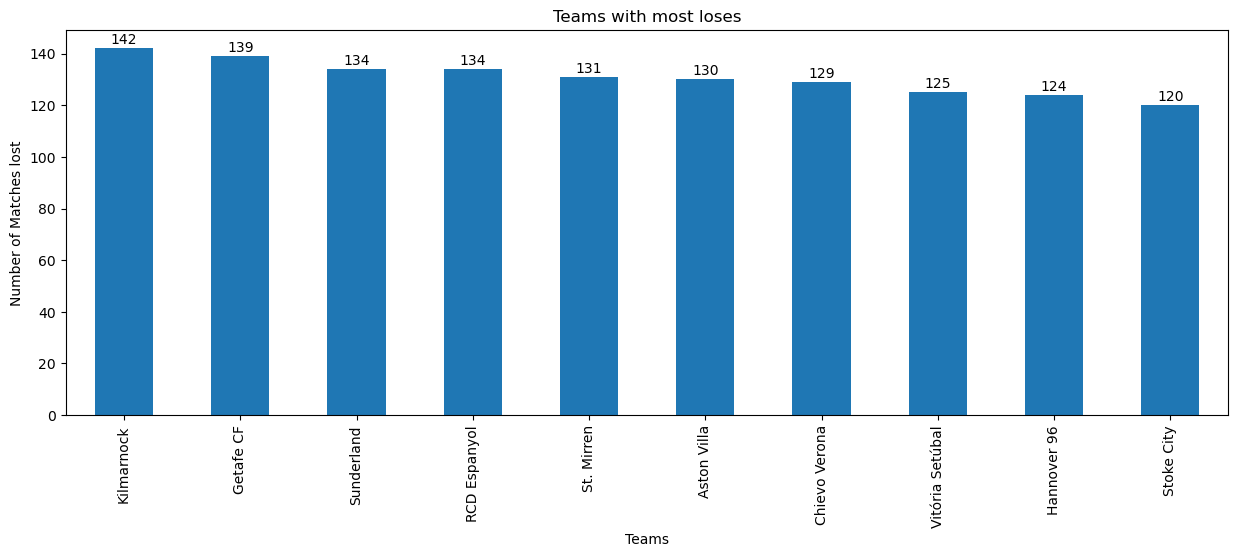

In [411]:

#sns.countplot(data=df1, x='match_result')

ax = top_team_with_most_loses.head(10).plot(kind = 'bar', figsize = (15,5))

plt.title("Teams with most loses")
plt.xlabel("Teams")
plt.ylabel("Number of Matches lost")
ax.bar_label(ax.containers[0], padding=1)

plt.show()

#### Conclusion

The bar chart displays the top 10 teams with the highest number of match losses. The team with the tallest bar has recorded the most losses among the selected teams.

This comparison helps identify teams that struggled to secure wins across the matches analyzed. 

In [412]:
# print("df2 shape:", df2.shape)
# print("df3 shape:", df3.shape)
# print("df_combined shape:", df_combined.shape)
#df_combined.head()

## 19. Analyzing Home Wins and Away Wins by the Teams

This step filters the dataset to select matches where the home team scored more goals than the away team. The filtered matches are then grouped by home team, and the number of wins for each team is counted.

This analysis helps identify which teams secured the most victories when playing on their home ground and provides insight into home advantage across the dataset.

In [413]:
home_wins = df_combined[
    df_combined['Home Team Goal'] > df_combined['Away Team Goal']].groupby('Home Team').size()

away_wins = df_combined[
    df_combined['Home Team Goal'] < df_combined['Away Team Goal']].groupby('Away Team').size()

In [414]:
# print(home_wins)

In [415]:
# print(away_wins)


## 20. Making comparision on Home Wins and Away Wins:

Finally, the teams are sorted by total wins in descending order, and the top 10 teams are selected.

This analysis helps compare teams' performance at home and away and identify the teams with the highest overall number of victories.

In [416]:
comparison = comparison.astype(int)

#comparison.head()

comparison = pd.concat([
    home_wins.rename_axis('Team').rename('Home Wins'),
    away_wins.rename_axis('Team').rename('Away Wins')
], axis=1).fillna(0)

comparison['Total Wins'] = comparison['Home Wins'] + comparison['Away Wins']

comparison = comparison.sort_values(
    ascending=False, by='Total Wins'
).head(10)

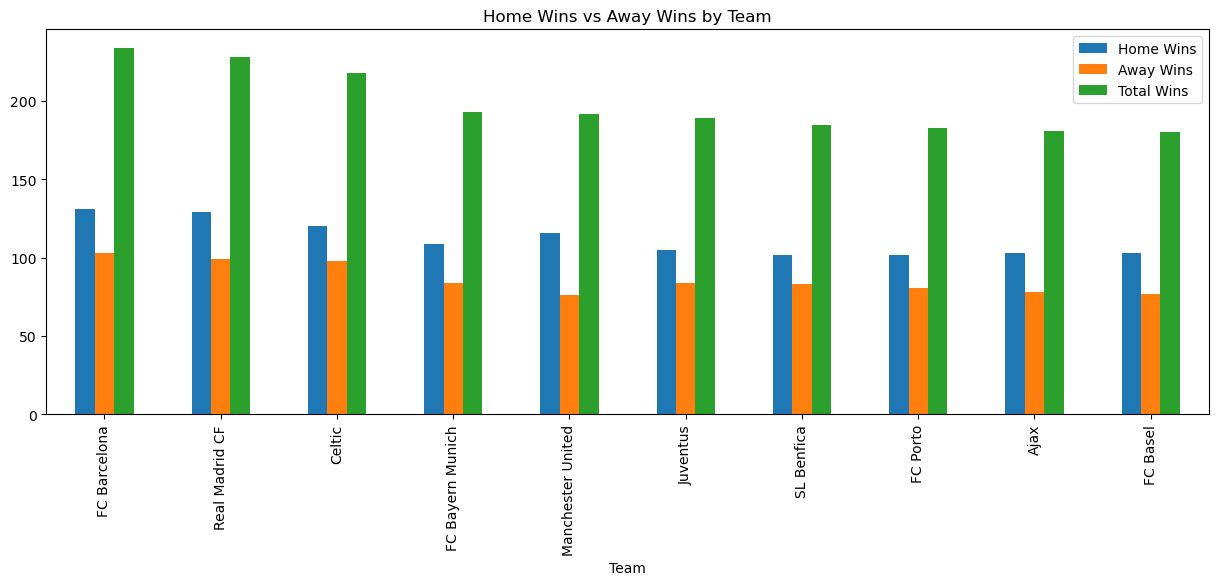

In [417]:
comparison[['Home Wins','Away Wins','Total Wins']].plot(kind = 'bar', figsize = (15,5), title = 'Home Wins vs Away Wins by Team')

xlabel = 'Teams'
ylabel = 'No of Wins'
plt.show()

# Conclusion

This project explored football match data using Python, Pandas, NumPy, Matplotlib, Seaborn, and SQL to understand match outcomes, goal-scoring patterns, and team performance.

The analysis produced the following key findings:

1. **Match Results and Home Advantage:** Home wins accounted for approximately 45.9% of matches, compared with 28.7% for away wins and 25.4% for draws. This suggests that home teams had an advantage in the matches analyzed.

2. **Goal-Scoring Patterns:** The analysis of average goals scored by home and away teams helped compare their scoring performance and investigate differences between playing at home and away.

3. **Highest-Scoring Matches:** Identifying the top 10 matches by total goals highlighted games with particularly high scoring and enabled comparisons between home and away team performances.

4. **Seasonal Goal Analysis:** Grouping matches by season helped identify seasons with the highest total goals and compare the contributions of home and away teams. These totals should be interpreted in the context of the number of matches played in each season.

5. **Team Performance:** By combining match records with team information, the analysis identified teams with the most wins, teams with the most losses, and teams with strong home and away records. FC Barcelona recorded 234 wins, followed by Real Madrid CF with 228 wins and Celtic with 218 wins in the analyzed dataset.

6. **Data Manipulation and Visualization:** The project demonstrated the practical use of SQL queries, Pandas grouping and merging, conditional statements, sorting, and bar charts to transform raw football data into meaningful insights.

## Overall Conclusion

The analysis shows that football match outcomes and team performance can be examined effectively through exploratory data analysis. Home and away comparisons, seasonal goal totals, high-scoring matches, and team win-loss records provide different perspectives on performance.

This project strengthened my understanding of data extraction, data manipulation, aggregation, merging datasets, and visualization using Python. It also demonstrated how data analysis can help uncover patterns and support evidence-based conclusions in sports analytics.